# LeetCode #494: Target Sum

https://leetcode.com/problems/target-sum/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (Recursion)** | $O(2^n)$ | $O(n)$ |
| **Optimal: DP / Subset Sum ★** | $O(n \cdot S)$ | $O(S)$ |

---

## Understanding the Methods

### Brute Force (Recursion)
For each number, try both adding and subtracting it. Recurse through all 2^n combinations and count those that reach the target.

### Optimal: DP / Subset Sum ★
Reframe the problem: let P be the set of numbers with `+` and N be the set with `-`. Then sum(P) - sum(N) = target and sum(P) + sum(N) = totalSum. So sum(P) = (target + totalSum) / 2. This reduces to counting subsets that sum to (target + totalSum) / 2, which is a classic 0/1 knapsack problem solvable in O(n*S) time.

**Why this is better than Brute Force:** The DP approach avoids recomputing overlapping subproblems, reducing exponential time to pseudo-polynomial.

**Constraints:**
* 1 <= nums.length <= 20
* 0 <= nums[i] <= 1000
* 0 <= sum(nums[i]) <= 1000
* -1000 <= target <= 1000

## Solutions

### C#

In [ ]:
public class Solution {
    public int FindTargetSumWays(int[] nums, int target) {
        int total = nums.Sum();
        if ((total + target) % 2 != 0 || total + target < 0) return 0;
        int s = (total + target) / 2;
        int[] dp = new int[s + 1];
        dp[0] = 1;
        foreach (int n in nums)
            for (int j = s; j >= n; j--)
                dp[j] += dp[j - n];
        return dp[s];
    }
}

### Python

In [ ]:
class Solution:
    def findTargetSumWays(self, nums: list[int], target: int) -> int:
        total = sum(nums)
        if (total + target) % 2 != 0 or total + target < 0:
            return 0
        s = (total + target) // 2
        dp = [0] * (s + 1)
        dp[0] = 1
        for n in nums:
            for j in range(s, n - 1, -1):
                dp[j] += dp[j - n]
        return dp[s]

### Go

In [ ]:
func findTargetSumWays(nums []int, target int) int {
    total := 0
    for _, n := range nums { total += n }
    if (total+target)%2 != 0 || total+target < 0 { return 0 }
    s := (total + target) / 2
    dp := make([]int, s+1)
    dp[0] = 1
    for _, n := range nums {
        for j := s; j >= n; j-- {
            dp[j] += dp[j-n]
        }
    }
    return dp[s]
}

### Rust

In [ ]:
impl Solution {
    pub fn find_target_sum_ways(nums: Vec<i32>, target: i32) -> i32 {
        let total: i32 = nums.iter().sum();
        if (total + target) % 2 != 0 || total + target < 0 { return 0; }
        let s = ((total + target) / 2) as usize;
        let mut dp = vec![0i32; s + 1];
        dp[0] = 1;
        for &n in &nums {
            let n = n as usize;
            for j in (n..=s).rev() {
                dp[j] += dp[j - n];
            }
        }
        dp[s]
    }
}

## Example Scenarios

### 1. Common Case — Three Ones, Target 1

**Input:** `nums = [1,1,1], target = 1`

The $2^3 = 8$ sign assignments give sums $\{3,1,1,-1,1,-1,-1,-3\}$, so `3` of them hit the target. Reframed as subset sum: $S = (\text{total} + \text{target})/2 = (3+1)/2 = 2$, and there are exactly 3 subsets of `[1,1,1]` summing to 2.

### 2. Slightly Complex — Distinct Values, Target 0

**Input:** `nums = [1,2,3], target = 0`

Only $+1+2-3$ and $-1-2+3$ reach 0, so the answer is `2`. The subset target is $S = (6+0)/2 = 3$, satisfied by $\{3\}$ and $\{1,2\}$ — the same two solutions seen from the other side. If $\text{total} + \text{target}$ were odd, no split could exist and the answer would be `0` immediately.

### 3. Edge Case: Time Factor — Exponential Tree vs. Pseudo-Polynomial DP

**Input:** `nums = [1,1,1,1,1], target = 3`

The decision tree has $2^5 = 32$ leaves and `5` of them land on 3. At the constraint limit $n = 20$ that tree holds $2^{20} \approx 10^6$ leaves, while the DP needs only $n \cdot S \le 20 \times 1000 = 2 \times 10^4$ cell updates — the whole reason for the reformulation.

### 4. Edge Case: Space Factor — Largest Possible DP Array

**Input:** `nums = [1000], target = 1000`

Here $S = (1000 + 1000)/2 = 1000$, the maximum allowed by the constraints, so the rolling DP array holds 1001 entries for a single input number. Only `+1000` works, giving `1` way — the memory is driven by $S$, not by $n$.

### 5. Almost-Impossible but Plausible — Zeros Double Every Count

**Input:** `nums = [0,0,0,0,0,0,0,0,1], target = 1`

Each `0` can carry `+` or `-` without changing the sum, so every zero doubles the number of valid assignments: $2^8 = 256$, all of them using `+1`. In the DP this shows up as `dp[0]` doubling on each zero (1, 2, 4, …, 256) before the final `1` carries that count to `dp[1]`. A solution that de-duplicates subsets instead of counting assignments wrongly returns `1`.


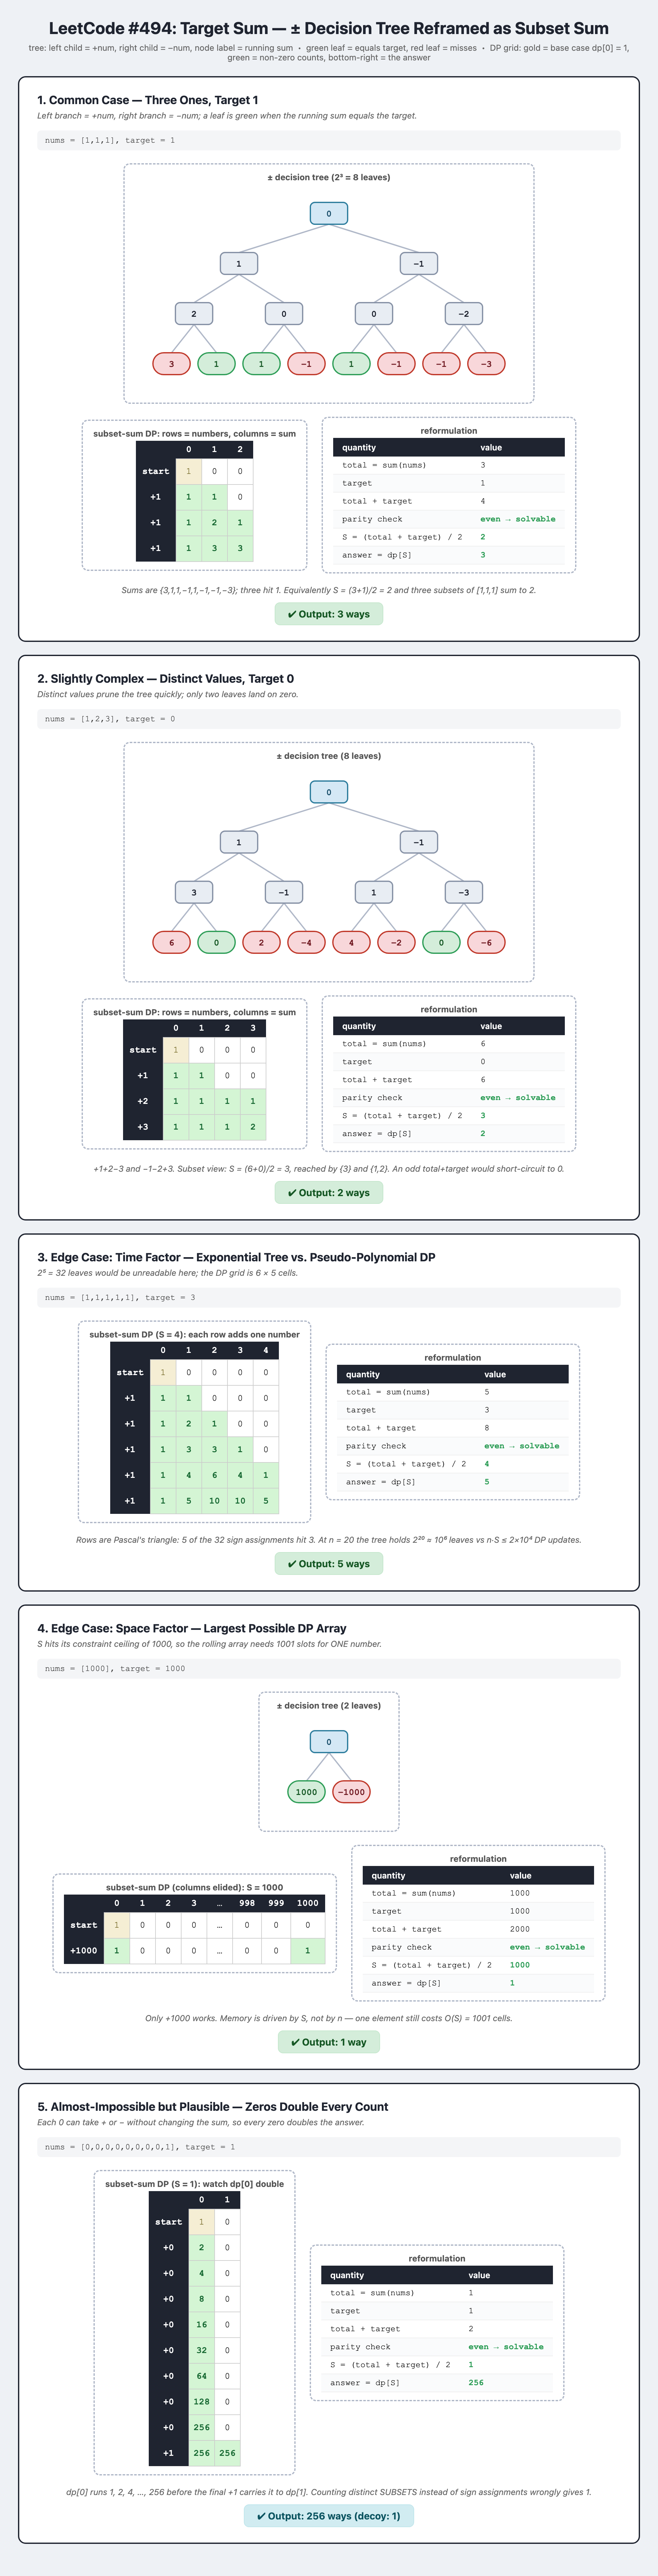